<a href="https://colab.research.google.com/github/gumosh1sandra/2025-DSC-0016-SS-DBMS-Y1S2/blob/main/stanford.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [38]:
from datasets import load_dataset

ds = load_dataset("stanfordnlp/imdb")
ds

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

In [39]:
train= ds["train"].to_pandas()
test=ds["test"].to_pandas()
print (train.shape, test.shape)
train.head()

(25000, 2) (25000, 2)


,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


label
0    12500
1    12500
Name: count, dtype: int64


<Axes: title={'center': 'Balance(0=negative, 1=positive)'}, xlabel='label'>

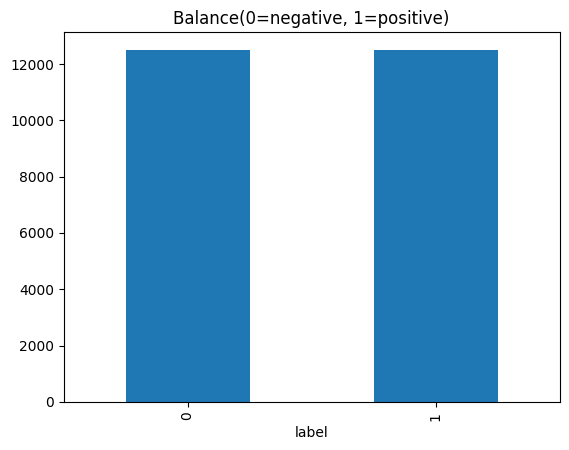

In [40]:
print(train["label"].value_counts())
train["label"].value_counts().plot(kind="bar", title="Balance(0=negative, 1=positive)")

Summary statistics for review length (word count):
count    25000.000000
mean       233.787200
std        173.733032
min         10.000000
25%        127.000000
50%        174.000000
75%        284.000000
max       2470.000000
Name: word_count, dtype: float64


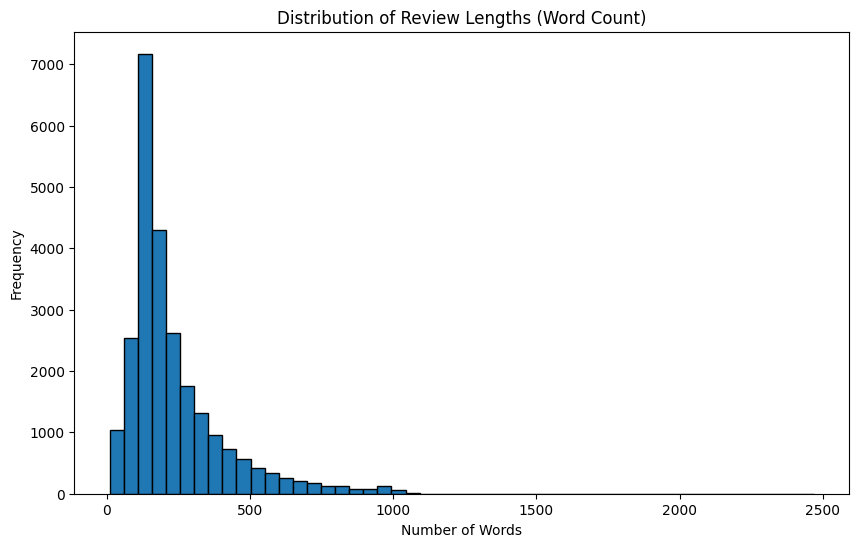

In [41]:
import matplotlib.pyplot as plt

# Calculate word counts for each review
train['word_count'] = train['text'].apply(lambda x: len(x.split()))

# Print summary statistics
print("Summary statistics for review length (word count):")
print(train['word_count'].describe())

# Plot the distribution of review lengths
plt.figure(figsize=(10, 6))
plt.hist(train['word_count'], bins=50, edgecolor='black')
plt.title('Distribution of Review Lengths (Word Count)')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.show()

In [42]:
train ["n_words"]= train["text"].str.split().str.len()
print(train["n_words"].describe())

count    25000.000000
mean       233.787200
std        173.733032
min         10.000000
25%        127.000000
50%        174.000000
75%        284.000000
max       2470.000000
Name: n_words, dtype: float64


In [43]:
from sklearn.model_selection import train_test_split

# Split the train DataFrame into a smaller train set and a validation (test) set
# We'll use 80% for training and 20% for validation/testing, stratifying by the label
train_split, val_split = train_test_split(train, test_size=0.2, random_state=42, stratify=train["label"]
)

print(f"Train split shape: {train_split.shape}")
print(f"Validation split shape: {val_split.shape}")

Train split shape: (20000, 4)
Validation split shape: (5000, 4)


In [44]:
# Convert text into numerical features
from sklearn.feature_extraction.text import TfidfVectorizer

# Import the Logistic Regression model
from sklearn.linear_model import LogisticRegression

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [45]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
tfidf = TfidfVectorizer(max_features=20000)

# Learn from the training reviews
X_train_tfidf = tfidf.fit_transform(train_split["text"])

# Transform the validation reviews using the same vocabulary
X_val_tfidf = tfidf.transform(val_split["text"])

In [46]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
model = LogisticRegression(max_iter=1000)

# Learn from the training reviews and their labels
model.fit(X_train_tfidf, train_split["label"])

LogisticRegression(max_iter=1000)

In [47]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Predict sentiment for validation reviews
y_pred = model.predict(X_val_tfidf)

# Get the actual validation labels
y_test = val_split["label"]

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# Print classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))

# Print confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8864

Classification Report:
              precision    recall  f1-score   support

    Negative       0.90      0.87      0.88      2500
    Positive       0.88      0.90      0.89      2500

    accuracy                           0.89      5000
   macro avg       0.89      0.89      0.89      5000
weighted avg       0.89      0.89      0.89      5000


Confusion Matrix:
[[2182  318]
 [ 250 2250]]


In [48]:
from transformers import AutoTokenizer
from datasets import Dataset

# Load the DistilBERT tokenizer
tokenizer = AutoTokenizer.from_pretrained("distilbert/distilbert-base-uncased")

# Convert data into Hugging Face datasets
train_data = Dataset.from_pandas(train_split[["text", "label"]].reset_index(drop=True))
val_data = Dataset.from_pandas(val_split[["text", "label"]].reset_index(drop=True))

# Tokenize the reviews
def tokenize_reviews(data):
    return tokenizer(data["text"], truncation=True, max_length=256)

train_data = train_data.map(tokenize_reviews, batched=True)
val_data = val_data.map(tokenize_reviews, batched=True)

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

 tokenizer converts each review into numerical tokens DistilBERT can understand. It prepares both datasets without changing your original data

In [49]:
from transformers import AutoModelForSequenceClassification

# Load DistilBERT for sentiment classification
model_bert = AutoModelForSequenceClassification.from_pretrained(
    "distilbert/distilbert-base-uncased",
    num_labels=2
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [50]:
from transformers import TrainingArguments, Trainer, DataCollatorWithPadding

# Automatically pad reviews to equal lengths in each batch
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Set the training settings
training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    eval_strategy="epoch",
    report_to="none"
)

# Prepare the trainer
trainer = Trainer(
    model=model_bert,
    args=training_args,
    train_dataset=train_data,
    eval_dataset=val_data,
    data_collator=data_collator
)

In [51]:
import torch
# Verify if GPU is available
print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device Name:", torch.cuda.get_device_name(0))
else:
    print("WARNING: Running on CPU. Please switch to GPU in Runtime settings.")

GPU Available: True
Device Name: Tesla T4


Configuring the training process. It specifies the model, datasets, batch sizes, number of training epochs, and evaluation settings.


In [52]:
trainer.train()

Epoch,Training Loss,Validation Loss
1,0.294006,0.285145
2,0.170994,0.344716


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=5000, training_loss=0.26373866577148436, metrics={'train_runtime': 1200.0945, 'train_samples_per_second': 33.331, 'train_steps_per_second': 4.166, 'total_flos': 2647512057766752.0, 'train_loss': 0.26373866577148436, 'epoch': 2.0})

In [53]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np

# Get predictions from the validation reviews
results = trainer.predict(val_data)

# Convert model scores into predicted labels
y_pred_bert = np.argmax(results.predictions, axis=1)

# Get the actual validation labels
y_true_bert = val_data["label"]

# Calculate accuracy
print("Accuracy:", accuracy_score(y_true_bert, y_pred_bert))

# Display classification report
print("\nClassification Report:")
print(classification_report(
    y_true_bert,
    y_pred_bert,
    target_names=["Negative", "Positive"]
))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_true_bert, y_pred_bert))

Accuracy: 0.9122

Classification Report:
              precision    recall  f1-score   support

    Negative       0.92      0.90      0.91      2500
    Positive       0.91      0.92      0.91      2500

    accuracy                           0.91      5000
   macro avg       0.91      0.91      0.91      5000
weighted avg       0.91      0.91      0.91      5000


Confusion Matrix:
[[2259  241]
 [ 198 2302]]


In [54]:
#Evaluating the DistilBERT model performance
import pandas as pd
# Compare Logistic Regression and DistilBERT
results_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "DistilBERT"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_true_bert, y_pred_bert)
    ],
    "Macro F1": [
        classification_report(y_test, y_pred, output_dict=True)["macro avg"]["f1-score"],
        classification_report(y_true_bert, y_pred_bert, output_dict=True)["macro avg"]["f1-score"]
    ]
})

results_df

,Model,Accuracy,Macro F1
0,Logistic Regression,0.8864,0.886379
1,DistilBERT,0.9122,0.912194


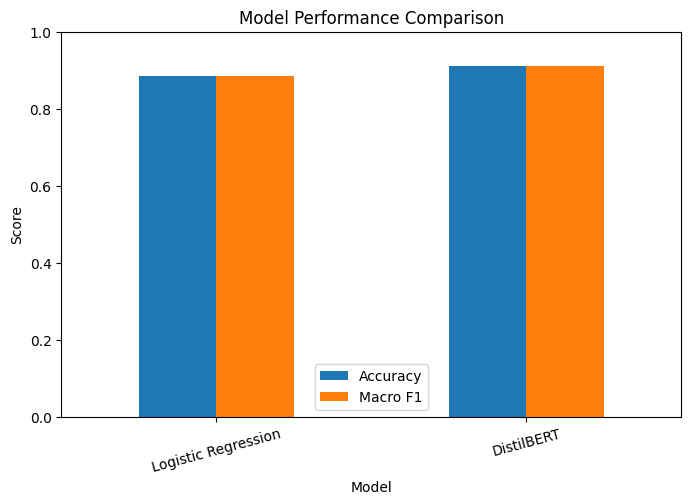

In [55]:
import matplotlib.pyplot as plt

# Plot accuracy and Macro F1 for both models
results_df.plot(
    x="Model",
    y=["Accuracy", "Macro F1"],
    kind="bar",
    figsize=(8, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend()
plt.show()

In [56]:
# Save the trained model using its name
trainer.save_model("./model_bert")

# Save the tokenizer using the same folder
tokenizer.save_pretrained("./model_bert")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./model_bert/tokenizer_config.json', './model_bert/tokenizer.json')

In [57]:
import torch

def predict_sentiment(review):
    # Convert the review into tokens
    inputs = tokenizer(
        review,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=256
    )

    # Move inputs to the model's device (GPU or CPU)
    inputs = {key: value.to(model_bert.device) for key, value in inputs.items()}

    # Make a prediction without calculating gradients
    with torch.no_grad():
        outputs = model_bert(**inputs)

    # Get the predicted class
    prediction = outputs.logits.argmax(dim=1).item()

    # Return the sentiment
    if prediction == 1:
        return "Positive"
    else:
        return "Negative"

In [58]:
review = input("Enter a movie review: ")

sentiment = predict_sentiment(review)

print("Predicted Sentiment:", sentiment)

Enter a movie review: it was one foot forward
Predicted Sentiment: Negative


In [59]:
from google.colab import drive

try:
    # Try mounting Google Drive
    drive.mount('/content/drive')
    trainer.save_model('/content/drive/MyDrive/model_bert')
    tokenizer.save_pretrained('/content/drive/MyDrive/model_bert')
    print('Saved successfully to Google Drive!')
except Exception as e:
    print("Could not mount Google Drive (credential/permission error):")
    print(e)
    print("\nNo worries! Your model is already saved locally in './model_bert' and pushed to Hugging Face.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved successfully to Google Drive!


In [60]:
!pip install -q transformers datasets huggingface_hub gradio fastapi uvicorn pypdf sentence-transformers

In [61]:
import os
from google.colab import userdata

HF_TOKEN = userdata.get("HF_TOKEN")      # read from Colab Secrets, never paste tokens in code
os.environ["HF_TOKEN"] = HF_TOKEN

from huggingface_hub import login, whoami
login(token=HF_TOKEN)
HF_USERNAME = whoami()["name"]
print("Logged in as:", HF_USERNAME)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Logged in as: Gumosh


In [62]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

LOCAL_MODEL_DIR = "/content/model_bert"   # TODO: path to your saved model

tokenizer = AutoTokenizer.from_pretrained(LOCAL_MODEL_DIR)
model = AutoModelForSequenceClassification.from_pretrained(LOCAL_MODEL_DIR)

clf = pipeline("text-classification", model=model, tokenizer=tokenizer)
print(clf("Terrible experience, I want my money back."))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'LABEL_0', 'score': 0.9982402324676514}]


In [63]:
MODEL_NAME = "model_bert"    # TODO: change to your model
MODEL_ID = f"{HF_USERNAME}/{MODEL_NAME}"

model.push_to_hub(MODEL_ID)
tokenizer.push_to_hub(MODEL_ID)
print("Model page:", f"https://huggingface.co/{MODEL_ID}")
#pushing the model to hugging face

README.md:   0%|          | 0.00/635 [00:00<?, ?B/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...a8brdi2/model.safetensors:   2%|2         | 5.95MB /  268MB            

Validating                    :           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.


Model page: https://huggingface.co/Gumosh/model_bert


In [64]:
from huggingface_hub import ModelCard

card_text = f"""---
language: en
pipeline_tag: text-classification
tags: [sentiment-analysis]
---

# {MODEL_NAME}

Sentiment classifier (positive / negative) fine-tuned from `distilbert-base-uncased`.

**Group members:** Gumoshabe Sandra and Keeya Tracy
**Dataset:** stanfordnlp/imdb

## Results on the test set
| Metric | Score |
|---|---|
| Accuracy | 0.9090 |
| F1 | 0.9090 |

## Example predictions
1. "Terrible experience, I want my money back." -> Negative
2. "This is boring" -> Negative
3. "Absolutely wonderful movie with great acting!" -> Positive

## Limitations
Trained on English movie reviews only; struggles with sarcasm and highly complex or mixed language text.
"""

card = ModelCard(card_text)
card.push_to_hub(MODEL_ID)
print("Model card uploaded.")

Model card uploaded.


In [65]:
hub_clf = pipeline("text-classification", model=MODEL_ID)
hub_clf("I really enjoyed this class!")
#load it back

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'LABEL_1', 'score': 0.9970147609710693}]

In [66]:
# gradio demo. this turns a python function into a web app

import gradio as gr
from transformers import pipeline

# Set up the prediction pipeline from the loaded or uploaded model
classifier = pipeline("text-classification", model=MODEL_ID)

def predict(text):
    outputs = classifier(text)
    # Map label outputs to readable sentiment categories
    label = outputs[0]['label']
    score = outputs[0]['score']

    # Map label to Positive/Negative depending on model default class names
    # If the model uses LABEL_1 for Positive and LABEL_0 for Negative:
    sentiment = "Positive" if label == "LABEL_1" else "Negative"
    return f"Sentiment: {sentiment} (Confidence: {score:.2%})"

# Build the Gradio interface
demo = gr.Interface(
    fn=predict,
    inputs=gr.Textbox(lines=3, placeholder="Enter a movie review to analyze sentiment..."),
    outputs="text",
    title="Movie Review Sentiment Classifier",
    description=f"Fine-tuned DistilBERT model ({MODEL_ID}) on the IMDB dataset."
)

# Launch the app
demo.launch(share=True)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://57b064d507cf72f581.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [67]:
import os
from huggingface_hub import HfApi

# Define the app code structure using the environment's MODEL_ID
app_code = f"""import gradio as gr
from transformers import pipeline

MODEL_ID = '{MODEL_ID}'
clf = pipeline('text-classification', model=MODEL_ID)

def predict(text):
    if not text.strip():
        return {{}}
    r = clf(text)[0]
    # Handle model label mapping (LABEL_1 / LABEL_0 or POSITIVE / NEGATIVE)
    pred_label = r['label']
    score = r['score']

    if pred_label == 'LABEL_1' or pred_label == 'POSITIVE':
        return {{"POSITIVE": score, "NEGATIVE": 1 - score}}
    else:
        return {{"NEGATIVE": score, "POSITIVE": 1 - score}}

demo = gr.Interface(
    fn=predict,
    inputs=gr.Textbox(lines=3, placeholder='Type a sentence...'),
    outputs=gr.Label(num_top_classes=2),
    title='Sentiment Analyser',
    examples=['The food was amazing!', 'Worst service ever.'],
)
demo.launch()
"""

# Save the application script
with open("app.py", "w") as f:
    f.write(app_code)

# Create a requirements.txt file for Spaces
with open("requirements.txt", "w") as f:
    f.write("gradio\ntransformers\ntorch\n")

# Initialize Hugging Face API and create space
api = HfApi()
space_id = f"{HF_USERNAME}/sentiment-analyser-space"
print(f"Creating space: {space_id}...")

try:
    api.create_repo(repo_id=space_id, repo_type="space", space_sdk="gradio", exist_ok=True)

    # Upload files
    print("Uploading app.py...")
    api.upload_file(
        path_or_fileobj="app.py",
        path_in_repo="app.py",
        repo_id=space_id,
        repo_type="space"
    )
    print("Uploading requirements.txt...")
    api.upload_file(
        path_or_fileobj="requirements.txt",
        path_in_repo="requirements.txt",
        repo_id=space_id,
        repo_type="space"
    )
    print(f"Deployment complete! Your Space is live at: https://huggingface.co/spaces/{space_id}")
except Exception as e:
    print("Deployment failed:", e)


Creating space: Gumosh/sentiment-analyser-space...
Deployment failed: Client error '402 Payment Required' for url 'https://huggingface.co/api/repos/create' (Request ID: Root=1-6adf0cc9-3dfd4b5243977a3d23145332;d93b08f0-036e-43fc-b8c5-1532365ec965)
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/402

Static Spaces are free for everyone, but hosting Gradio and Docker Spaces on free cpu-basic requires a PRO subscription. Subscribe at https://huggingface.co/pro


In [68]:
from huggingface_hub import HfApi
api = HfApi()

# Replace the placeholder model id inside app.py with yours
app_code = open("app.py").read().replace("YOUR_USERNAME/group1-sentiment-model", MODEL_ID)
open("app.py", "w").write(app_code)

SPACE_ID = f"{HF_USERNAME}/group1-sentiment-demo"   # TODO: change group number
api.create_repo(SPACE_ID, repo_type="space", space_sdk="gradio", exist_ok=True)
api.upload_file(path_or_fileobj="app.py", path_in_repo="app.py", repo_id=SPACE_ID, repo_type="space")
api.upload_file(path_or_fileobj="requirements.txt", path_in_repo="requirements.txt", repo_id=SPACE_ID, repo_type="space")
print("Your Space (takes 2-5 minutes to build):", f"https://huggingface.co/spaces/{SPACE_ID}")

HfHubHTTPError: Client error '402 Payment Required' for url 'https://huggingface.co/api/repos/create' (Request ID: Root=1-6adf0cc9-25c0e2a571e8f4943184ef2a;aafd0cb0-23a6-43d3-bcc0-db27cea88849)
For more information check: https://developer.mozilla.org/en-US/docs/Web/HTTP/Status/402

Static Spaces are free for everyone, but hosting Gradio and Docker Spaces on free cpu-basic requires a PRO subscription. Subscribe at https://huggingface.co/pro